# 10 · Hit / flop classifier
CPU runtime is enough.

- Duplicate tracks are removed (by Spotify URI and by track + artist), and the split is **grouped by artist**
  (64/16/20), so no artist is in more than one split. A chronological check trains on 2000s tracks and tests on
  2010s tracks by artists not seen in training.
- Seeded; 5 seeds reported as mean ± SD, with an explicit artist-disjoint validation set.
- Majority / logistic regression / random forest baselines, artist-bootstrap 95% CIs, confusion matrix and
  calibration (reliability curve, Brier score, ECE).

**Label definition** (from the dataset's README): a track is a *hit* (1) if it appeared in the weekly Billboard Hot 100
at least once in its decade. A *flop* (0) must not appear in that decade's hit list, its artist must not appear there
either, it must belong to a non-mainstream or avant-garde genre with no song in the hit list, and it must be available
in the US market. The classes are balanced by construction, and the decision threshold is 0.5.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import joblib, kagglehub
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
                             brier_score_loss, log_loss, classification_report, ConfusionMatrixDisplay)

OUT = "/content/drive/MyDrive/szakdolgozat/v2"
RES = f"{OUT}/results"
os.makedirs(RES, exist_ok=True); os.makedirs(f"{OUT}/models", exist_ok=True)
SEED = 42
SEEDS = [0, 1, 2, 3, 4]      # SEEDS[0] is the model exported to the webapp
FEATURES = ["danceability", "energy", "key", "loudness", "mode",
            "speechiness", "acousticness", "instrumentalness",
            "liveness", "valence", "tempo", "duration_ms",
            "time_signature", "chorus_hit", "sections"]

In [3]:
path = kagglehub.dataset_download("theoverman/the-spotify-hit-predictor-dataset")
df = pd.concat([pd.read_csv(f"{path}/dataset-of-00s.csv").assign(decade="00s"),
                pd.read_csv(f"{path}/dataset-of-10s.csv").assign(decade="10s")], ignore_index=True)
n0 = len(df)
df["artist_key"] = df.artist.str.lower().str.strip()
df["song_key"] = df.track.str.lower().str.strip() + " || " + df.artist_key
for k in ["uri", "song_key"]:
    # drop songs listed with contradicting labels, keep one copy of the rest
    df = df[df.groupby(k).target.transform("nunique") == 1].drop_duplicates(k)
df = df.reset_index(drop=True)
print(n0, "->", len(df), "tracks after de-duplication;", df.artist_key.nunique(), "artists")
df.target.value_counts()

100%|██████████| 3.09M/3.09M [00:00<00:00, 139MB/s]

Extracting files...


12270 -> 11909 tracks after de-duplication; 5845 artists


,count
target,
1,5999
0,5910


## Artist-grouped split (64 / 16 / 20)

In [4]:
def group_split(d, n_splits, seed=SEED):
    rest, held = next(StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed)
                      .split(d, d.target, d.artist_key))
    return d.iloc[rest], d.iloc[held]

trainval, test = group_split(df, 5)
train, val = group_split(trainval, 5)
assert not (set(train.artist_key) & set(test.artist_key)) and not (set(val.artist_key) & set(test.artist_key))
assert not (set(train.artist_key) & set(val.artist_key))
t2 = pd.DataFrame({s: [len(d), len(d) / len(df), d.target.mean(), d.artist_key.nunique()]
                   for s, d in [("train", train), ("val", val), ("test", test)]},
                  index=["samples", "share", "hit_rate", "artists"]).T.round(3)
t2.to_csv(f"{RES}/table2_hit_splits.csv"); t2

,samples,share,hit_rate,artists
train,7668.0,0.644,0.507,3740.0
val,1874.0,0.157,0.477,935.0
test,2367.0,0.199,0.515,1170.0


In [5]:
scaler = StandardScaler().fit(train[FEATURES])
Xtr, Xva, Xte = (scaler.transform(d[FEATURES]) for d in [train, val, test])
ytr, yva, yte = (d.target.values.astype(int) for d in [train, val, test])

def build_model():
    model = keras.Sequential([
        layers.Input(shape=(len(FEATURES),)),
        layers.Dense(64),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dropout(0.2),

        layers.Dense(32),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dropout(0.1),

        layers.Dense(16),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dropout(0.1),

        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

def train_keras(seed, Xtr, ytr, Xva, yva):
    """Adam 1e-3, BCE, batch 16, max 40 epochs, early stopping (patience 5); best-val-loss weights restored."""
    keras.utils.set_random_seed(seed)
    model = build_model()
    ckpt = f"/content/hit_best_seed{seed}.keras"
    h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=40, batch_size=16, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5),
                             keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True)])
    best_epoch = int(np.argmin(h.history["val_loss"])) + 1
    return keras.models.load_model(ckpt), best_epoch, len(h.history["val_loss"])

def clf_metrics(t, p):
    yhat = (p >= 0.5).astype(int)
    return {"accuracy": accuracy_score(t, yhat), "f1": f1_score(t, yhat), "precision": precision_score(t, yhat),
            "recall": recall_score(t, yhat), "roc_auc": roc_auc_score(t, p),
            "brier": brier_score_loss(t, p), "log_loss": log_loss(t, p)}

def ece(t, p, bins=10):
    b = np.minimum((p * bins).astype(int), bins - 1)
    return sum(abs(t[b == i].mean() - p[b == i].mean()) * (b == i).mean() for i in range(bins) if (b == i).any())

def group_bootstrap(t, p, groups, fn, n=1000, seed=0):
    """95% CI resampling whole artists, not single tracks."""
    rng = np.random.default_rng(seed)
    members = list(pd.Series(np.arange(len(t))).groupby(np.asarray(groups)).apply(np.array))
    stats = [fn(t[i], p[i]) for i in
             (np.concatenate([members[j] for j in rng.integers(0, len(members), len(members))]) for _ in range(n))]
    return np.percentile(stats, [2.5, 97.5])

## MLP over 5 seeds

In [6]:
runs, test_probs = [], {}
for seed in SEEDS:
    model, best_epoch, stopped = train_keras(seed, Xtr, ytr, Xva, yva)
    p = model.predict(Xte, verbose=0).ravel()
    test_probs[seed] = p
    runs.append({"seed": seed, "best_epoch": best_epoch, "stopped_epoch": stopped, **clf_metrics(yte, p), "ece": ece(yte, p)})
    if seed == SEEDS[0]:
        model.save(f"{OUT}/models/hit_or_flop_classifier.keras")
        joblib.dump(scaler, f"{OUT}/models/scaler.pkl")
runs = pd.DataFrame(runs)
runs.to_csv(f"{RES}/hit_seed_runs.csv", index=False)
summary = runs.drop(columns="seed").agg(["mean", "std"]).T.round(4)
summary.to_csv(f"{RES}/hit_seed_summary.csv"); summary

,mean,std
best_epoch,8.6000,1.3416
stopped_epoch,13.6000,1.3416
accuracy,0.8316,0.0033
f1,0.8500,0.0026
precision,0.7846,0.0057
recall,0.9274,0.0065
roc_auc,0.9003,0.0025
brier,0.1211,0.0016
log_loss,0.3822,0.0039
ece,0.0267,0.0053


## Baselines with 95% artist-bootstrap CIs (test set)

In [7]:
candidates = {
    "Majority class": DummyClassifier(strategy="prior").fit(Xtr, ytr).predict_proba(Xte)[:, 1],
    "Logistic regression": LogisticRegression(max_iter=1000).fit(Xtr, ytr).predict_proba(Xte)[:, 1],
    "Random forest (300 trees)": RandomForestClassifier(300, random_state=SEED, n_jobs=-1).fit(Xtr, ytr).predict_proba(Xte)[:, 1],
    "MLP (seed 0, exported)": test_probs[SEEDS[0]],
}
acc = lambda t, p: accuracy_score(t, (p >= 0.5).astype(int))
rows = []
for name, p in candidates.items():
    a_ci = group_bootstrap(yte, p, test.artist_key, acc)
    auc_ci = group_bootstrap(yte, p, test.artist_key, roc_auc_score) if p.std() > 0 else [np.nan, np.nan]
    rows.append({"model": name, **{k: round(v, 3) for k, v in clf_metrics(yte, p).items()}, "ece": round(ece(yte, p), 3),
                 "acc_95ci": f"[{a_ci[0]:.3f}, {a_ci[1]:.3f}]", "auc_95ci": f"[{auc_ci[0]:.3f}, {auc_ci[1]:.3f}]"})
baselines = pd.DataFrame(rows)
baselines.to_csv(f"{RES}/table4_hit_baselines.csv", index=False); baselines

,model,accuracy,f1,precision,recall,roc_auc,brier,log_loss,ece,acc_95ci,auc_95ci
0,Majority class,0.515,0.679,0.515,1.000,0.500,0.250,0.693,0.008,"[0.463, 0.564]","[0.500, 0.500]"
1,Logistic regression,0.823,0.839,0.790,0.894,0.880,0.133,0.417,0.041,"[0.800, 0.844]","[0.855, 0.900]"
2,Random forest (300 trees),0.850,0.858,0.835,0.883,0.911,0.114,0.370,0.035,"[0.825, 0.872]","[0.891, 0.929]"
3,"MLP (seed 0, exported)",0.833,0.852,0.784,0.933,0.902,0.120,0.379,0.025,"[0.809, 0.856]","[0.880, 0.920]"


## Classification report, confusion matrix, calibration (seed 0 model)

              precision    recall  f1-score   support

        Flop      0.911     0.728     0.809      1149
         Hit      0.784     0.933     0.852      1218

    accuracy                          0.833      2367
   macro avg      0.847     0.830     0.830      2367
weighted avg      0.845     0.833     0.831      2367



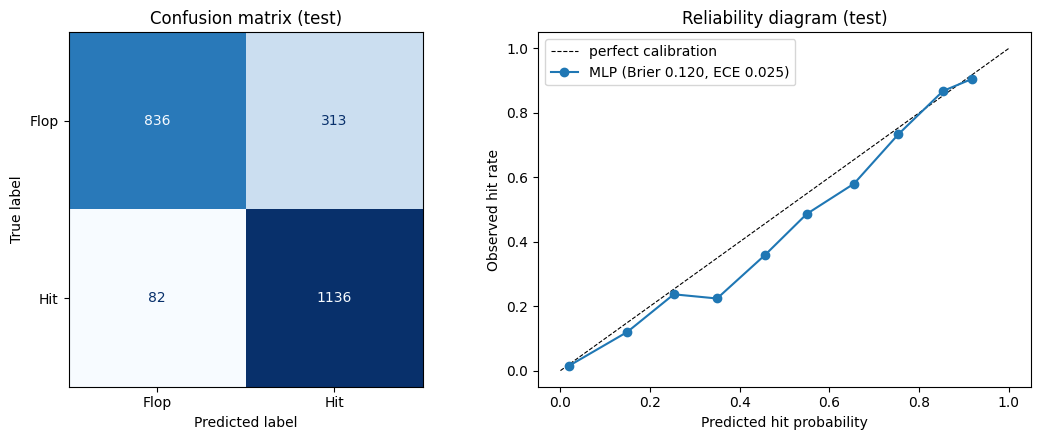

In [8]:
p0 = test_probs[SEEDS[0]]
yhat0 = (p0 >= 0.5).astype(int)
report = classification_report(yte, yhat0, target_names=["Flop", "Hit"], digits=3)
print(report); open(f"{RES}/hit_classification_report.txt", "w").write(report)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(yte, yhat0, display_labels=["Flop", "Hit"], cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (test)")
frac_pos, mean_pred = calibration_curve(yte, p0, n_bins=10)
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect calibration")
ax[1].plot(mean_pred, frac_pos, "o-", label=f"MLP (Brier {brier_score_loss(yte, p0):.3f}, ECE {ece(yte, p0):.3f})")
ax[1].set_xlabel("Predicted hit probability"); ax[1].set_ylabel("Observed hit rate"); ax[1].legend()
ax[1].set_title("Reliability diagram (test)")
plt.tight_layout(); plt.savefig(f"{RES}/fig_hit_confusion_calibration.png", dpi=200); plt.show()

## Chronological check: train on 2000s, test on 2010s (unseen artists only)

In [9]:
d00 = df[df.decade == "00s"]
d10 = df[(df.decade == "10s") & ~df.artist_key.isin(d00.artist_key)]
tr_c, va_c = group_split(d00, 5)
sc_c = StandardScaler().fit(tr_c[FEATURES])
m_c, _, _ = train_keras(SEEDS[0], sc_c.transform(tr_c[FEATURES]), tr_c.target.values,
                        sc_c.transform(va_c[FEATURES]), va_c.target.values)
X10 = sc_c.transform(d10[FEATURES])
chrono = pd.DataFrame({
    "MLP": clf_metrics(d10.target.values, m_c.predict(X10, verbose=0).ravel()),
    "Logistic regression": clf_metrics(d10.target.values, LogisticRegression(max_iter=1000)
                                       .fit(sc_c.transform(tr_c[FEATURES]), tr_c.target).predict_proba(X10)[:, 1]),
}).T.round(3)
chrono["n_test"] = len(d10)
chrono.to_csv(f"{RES}/hit_chronological.csv"); chrono

,accuracy,f1,precision,recall,roc_auc,brier,log_loss,n_test
MLP,0.771,0.792,0.681,0.946,0.871,0.163,0.494,4781
Logistic regression,0.773,0.787,0.695,0.906,0.855,0.160,0.498,4781


In [10]:
out = test[["uri", "track", "artist", "artist_key", "decade", "target"] + FEATURES].copy()
out["prob"] = p0
for s in SEEDS:
    out[f"prob_seed{s}"] = test_probs[s]
out.to_csv(f"{OUT}/hit_test_preds.csv", index=False)
print("saved", f"{OUT}/hit_test_preds.csv", "and models in", f"{OUT}/models")

saved /content/drive/MyDrive/szakdolgozat/v2/hit_test_preds.csv and models in /content/drive/MyDrive/szakdolgozat/v2/models
